# Book Recommender System – Machine Learning – Group 1

### Team Members:
- Nicole Bannert 
- Ariane Körner 
- Lorena Ruh 
- Leo Schladebach

### Aim 
[to be filled in]

### Data
Source (Kaggle): <https://www.kaggle.com/datasets/mohamedbakhet/amazon-books-reviews/data>

### Imports & Setup

In [1]:
import sys, numpy as np, pandas as pd
print(sys.executable)
print(np.__version__, pd.__version__)

/Users/I767516/Code/HWG/ML-Group-1/.venv/bin/python
2.5.5 3.1.1


In [8]:
import pandas as pd

df1 = pd.read_csv('../data/books_data.csv')
df2 = pd.read_csv('../data/Books_rating.csv')

df = pd.merge(df1, df2, on='Title', how='inner')
df.head()

,Title,description,authors,image,previewLink,publisher,publishedDate,infoLink,categories,ratingsCount,Id,Price,User_id,profileName,review/helpfulness,review/score,review/time,review/summary,review/text
0,Its Only Art If Its Well Hung!,NaN,['Julie Strain'],http://books.google.com/books/content?id=DykPA...,http://books.google.nl/books?id=DykPAAAACAAJ&d...,NaN,1996,http://books.google.nl/books?id=DykPAAAACAAJ&d...,['Comics & Graphic Novels'],NaN,1882931173,NaN,AVCGYZL8FQQTD,"Jim of Oz ""jim-of-oz""",7/7,4.0,940636800,Nice collection of Julie Strain images,This is only for Julie Strain fans. It's a col...
1,Dr. Seuss: American Icon,Philip Nel takes a fascinating look into the k...,['Philip Nel'],http://books.google.com/books/content?id=IjvHQ...,http://books.google.nl/books?id=IjvHQsCn_pgC&p...,A&C Black,2005-01-01,http://books.google.nl/books?id=IjvHQsCn_pgC&d...,['Biography & Autobiography'],NaN,0826414346,NaN,A30TK6U7DNS82R,Kevin Killian,10/10,5.0,1095724800,Really Enjoyed It,I don't care much for Dr. Seuss but after read...
2,Dr. Seuss: American Icon,Philip Nel takes a fascinating look into the k...,['Philip Nel'],http://books.google.com/books/content?id=IjvHQ...,http://books.google.nl/books?id=IjvHQsCn_pgC&p...,A&C Black,2005-01-01,http://books.google.nl/books?id=IjvHQsCn_pgC&d...,['Biography & Autobiography'],NaN,0826414346,NaN,A3UH4UZ4RSVO82,John Granger,10/11,5.0,1078790400,Essential for every personal and Public Library,"If people become the books they read and if ""t..."
3,Dr. Seuss: American Icon,Philip Nel takes a fascinating look into the k...,['Philip Nel'],http://books.google.com/books/content?id=IjvHQ...,http://books.google.nl/books?id=IjvHQsCn_pgC&p...,A&C Black,2005-01-01,http://books.google.nl/books?id=IjvHQsCn_pgC&d...,['Biography & Autobiography'],NaN,0826414346,NaN,A2MVUWT453QH61,"Roy E. Perry ""amateur philosopher""",7/7,4.0,1090713600,Phlip Nel gives silly Seuss a serious treatment,"Theodore Seuss Geisel (1904-1991), aka &quot;D..."
4,Dr. Seuss: American Icon,Philip Nel takes a fascinating look into the k...,['Philip Nel'],http://books.google.com/books/content?id=IjvHQ...,http://books.google.nl/books?id=IjvHQsCn_pgC&p...,A&C Black,2005-01-01,http://books.google.nl/books?id=IjvHQsCn_pgC&d...,['Biography & Autobiography'],NaN,0826414346,NaN,A22X4XUPKF66MR,"D. H. Richards ""ninthwavestore""",3/3,4.0,1107993600,Good academic overview,Philip Nel - Dr. Seuss: American IconThis is b...


Matplotlib is building the font cache; this may take a moment.


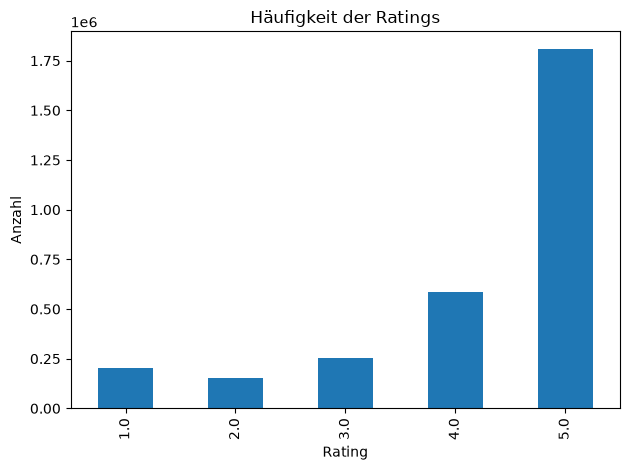

In [9]:
import matplotlib.pyplot as plt

df['review/score'].value_counts().sort_index().plot(kind='bar')
plt.xlabel('Rating')
plt.ylabel('Anzahl')
plt.title('Häufigkeit der Ratings')
plt.tight_layout()
plt.show()

In [ ]:
df['Price'].dropna().plot(kind='hist', bins=1000)
plt.xlabel('Preis')
plt.ylabel('Anzahl')
plt.title('Preisverteilung')
plt.xlim(0, 100)
plt.xticks(range(0, 101, 5))
plt.axvline(x=10, color='red')
plt.tight_layout()
plt.show()

In [13]:
print(f"Anzahl Zeilen/Spalten: {df.shape}")
df.describe(include='all')


Anzahl Zeilen/Spalten: (3000000, 19)


,Title,description,authors,image,previewLink,publisher,publishedDate,infoLink,categories,ratingsCount,Id,Price,User_id,profileName,review/helpfulness,review/score,review/time,review/summary,review/text
count,2999792,2359775,2609366,2459694,2669377,2217383,2645419,2669377,2448502,1.639306e+06,3000000,481171.000000,2438213,2438095,3000000,3.000000e+06,3.000000e+06,2999593,2999992
unique,212403,133226,127278,149387,188099,16016,11582,184506,10883,NaN,221998,NaN,1008972,854145,12084,NaN,NaN,1592314,2062648
top,The Hobbit,Celebrating 75 years of one of the world's mos...,['J. R. R. Tolkien'],http://books.google.com/books/content?id=LLSpn...,http://books.google.com/books?id=LLSpngEACAAJ&...,Penguin,2012,http://books.google.com/books?id=LLSpngEACAAJ&...,['Fiction'],NaN,B000IEZE3G,NaN,A14OJS0VWMOSWO,Midwest Book Review,0/0,NaN,NaN,Great Book,digital books are perfect and easy to use! The...
freq,22023,26396,37268,26396,22023,137071,49620,22023,824439,NaN,6796,NaN,5795,5817,885732,NaN,NaN,6848,322
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.720647e+02,NaN,21.762656,NaN,NaN,NaN,4.215289e+00,1.132307e+09,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.887721e+02,NaN,26.206541,NaN,NaN,NaN,1.203054e+00,1.493202e+08,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000e+00,NaN,1.000000,NaN,NaN,NaN,1.000000e+00,-1.000000e+00,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.000000e+00,NaN,10.780000,NaN,NaN,NaN,4.000000e+00,9.999072e+08,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000e+01,NaN,14.930000,NaN,NaN,NaN,5.000000e+00,1.128298e+09,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.500000e+01,NaN,23.950000,NaN,NaN,NaN,5.000000e+00,1.269130e+09,NaN,NaN


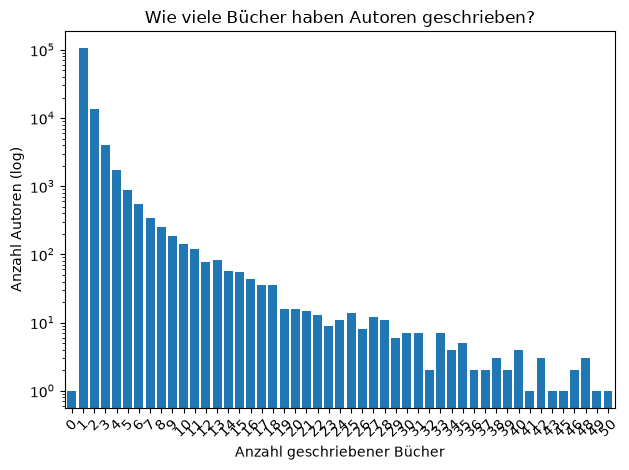

In [22]:
books_per_author = df1.drop_duplicates('Title').groupby('authors')['Title'].count()
author_dist = books_per_author.value_counts().sort_index()

author_dist[author_dist.index <= 50].plot(kind='bar', width=0.8)
plt.xlabel('Anzahl geschriebener Bücher')
plt.ylabel('Anzahl Autoren (log)')
plt.title('Wie viele Bücher haben Autoren geschrieben?')
plt.yscale('log')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

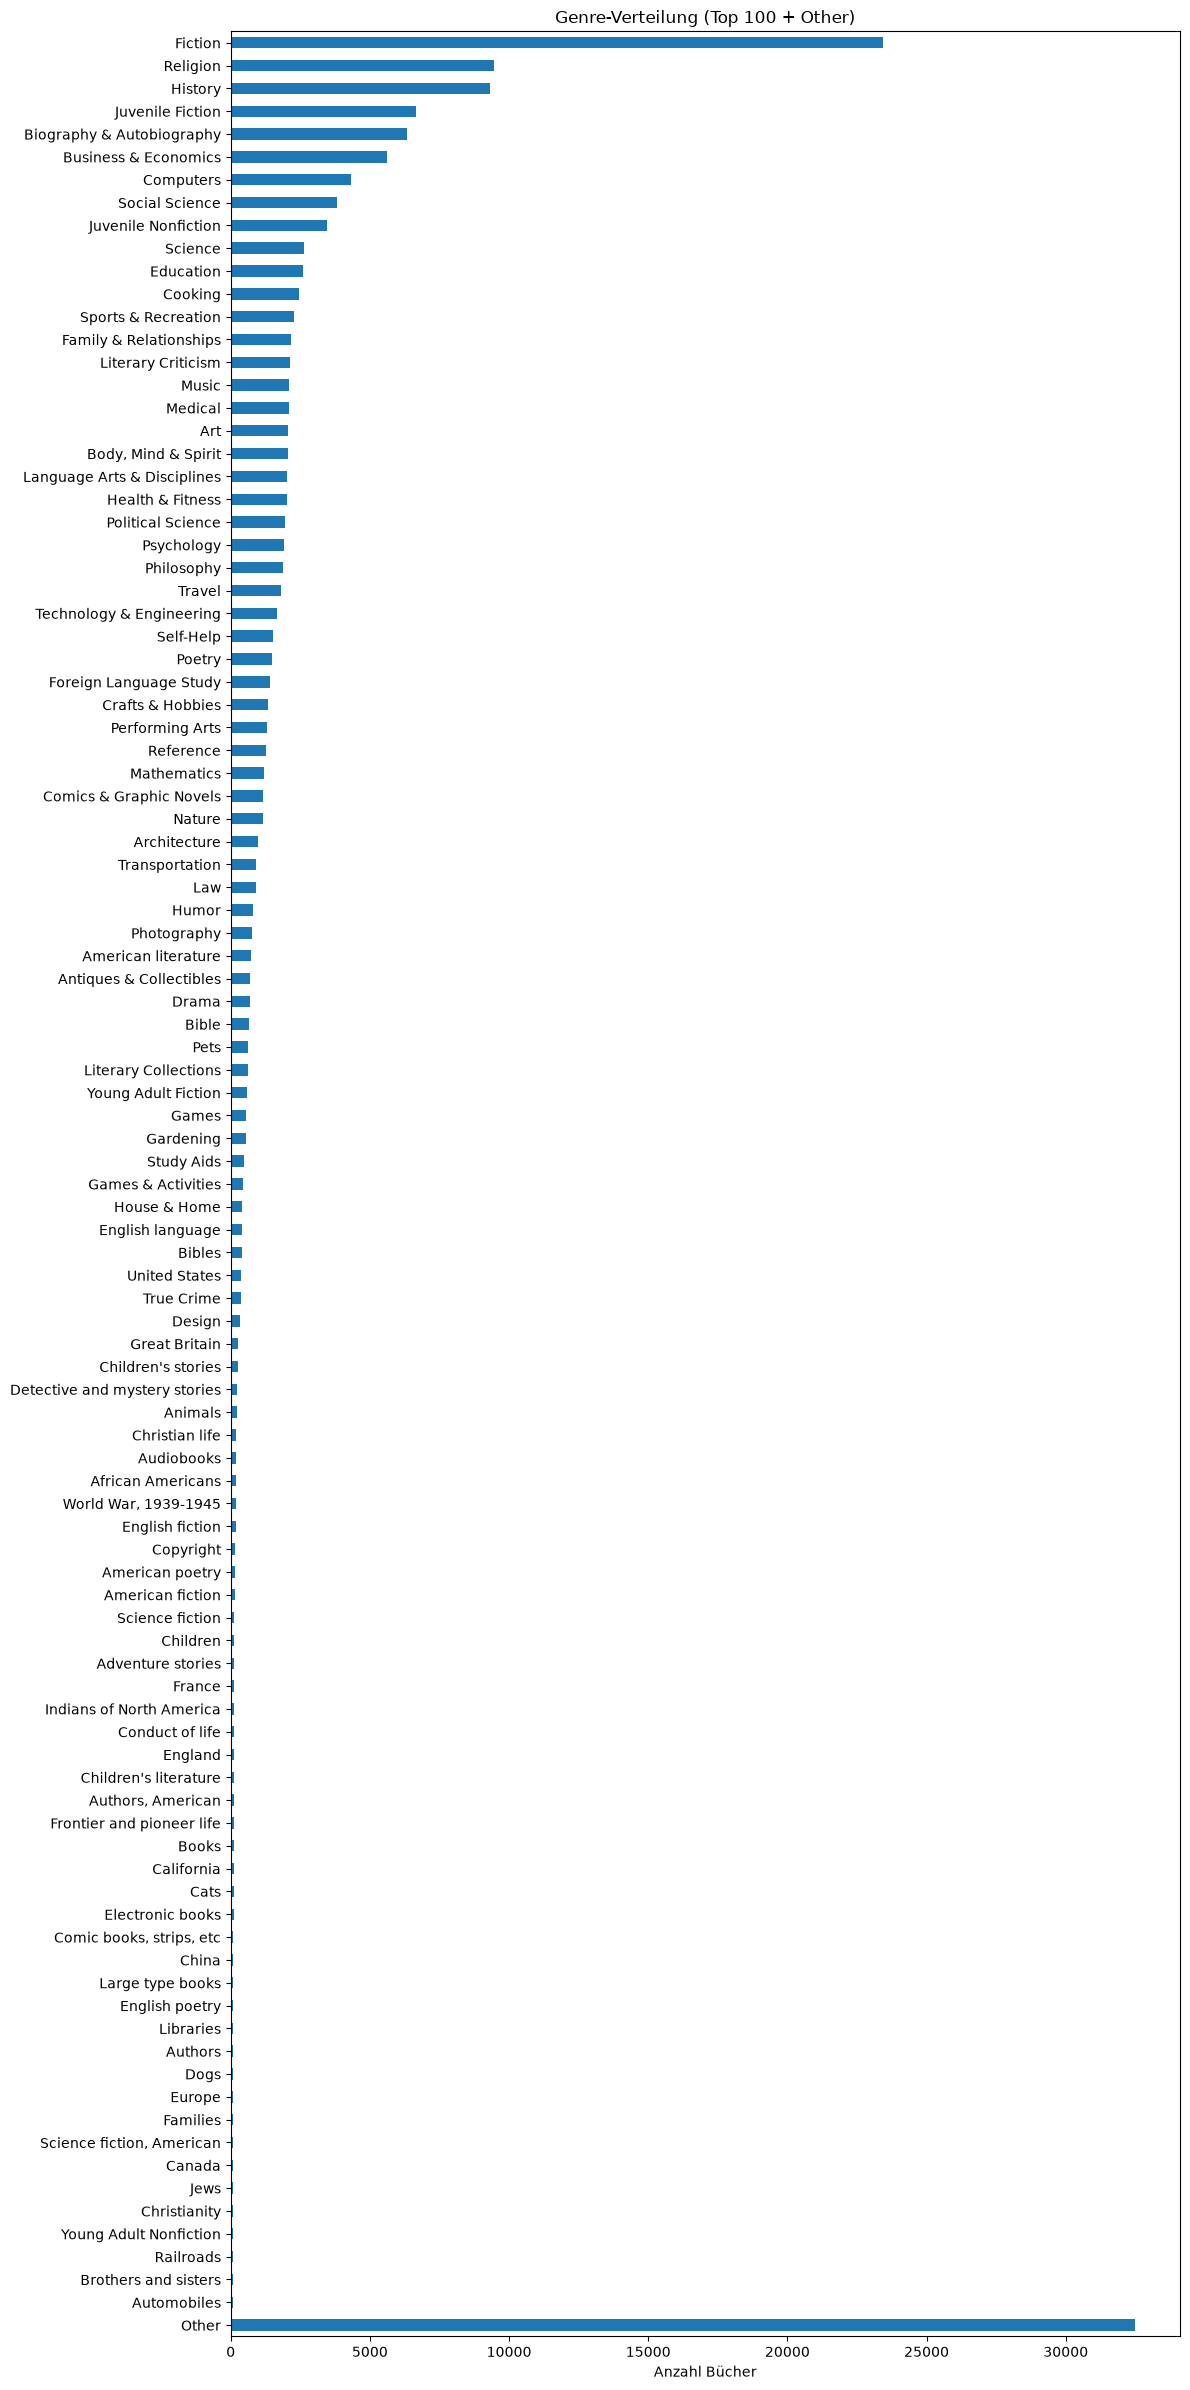

Datei gespeichert. 0.52% der Buecher nicht abgedeckt.


In [25]:
import ast

cats = df1.drop_duplicates('Title')['categories'].dropna()
cats_flat = cats.apply(lambda x: ast.literal_eval(x)[0] if x.startswith('[') else x)

counts = cats_flat.value_counts()
top100 = counts.head(100).sort_values()
other = pd.Series({'Other': counts.iloc[100:].sum()})
plot_data = pd.concat([other, top100])

plot_data.plot(kind='barh', figsize=(12, 24))
plt.xlabel('Anzahl Bücher')
plt.title('Genre-Verteilung (Top 100 + Other)')
plt.tight_layout()
plt.show()

top10000 = counts.head(10000)
not_included_pct = counts.iloc[10000:].sum() / counts.sum() * 100

with open('../data/top10000_genres.txt', 'w') as f:
    f.write(f'# {not_included_pct:.2f}% der Buecher gehoeren keinem der folgenden Top-10000-Genres an\n')
    for genre in top10000.index:
        f.write(genre + '\n')

print(f"Datei gespeichert. {not_included_pct:.2f}% der Buecher nicht abgedeckt.")

In [ ]:
years = df1.drop_duplicates('Title')['publishedDate'].dropna()
years = years.str.extract(r'(\d{4})')[0].astype(float)
years = years[(years >= 1800) & (years <= 2024)]

year_counts = years.value_counts().sort_index()
pre1950 = pd.Series({'< 1950': year_counts[year_counts.index < 1950].sum()})
post1950 = year_counts[year_counts.index >= 1950]
plot_data = pd.concat([pre1950, post1950])

plot_data.plot(kind='bar', width=0.9, figsize=(16, 5))
plt.xlabel('Jahr')
plt.ylabel('Anzahl Bücher')
plt.title('Bücher nach Erscheinungsjahr')
plt.xticks(rotation=90, fontsize=7)
plt.tight_layout()
plt.show()